## Sel 1: Setup

Impor library, set seed (`SEED = 42`), dan pilih `device` (CUDA, lalu MPS, lalu CPU).

In [1]:
import random
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42


def set_seed(seed):
    # Samakan seed di semua sumber acak supaya hasil bisa direproduksi
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device():
    # Prioritas: CUDA (Windows/Colab) -> MPS (Mac Apple Silicon) -> CPU
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


set_seed(SEED)
device = get_device()

print(f"Device            : {device}")
print(f"torch version     : {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")

Device            : mps
torch version     : 2.11.0
torchvision version: 0.26.0


## Sel 2: Konfigurasi

Kumpulkan parameter dataset di objek `cfg` supaya tidak ada angka hardcode.

In [2]:
@dataclass
class Config:
    image_size: int = 28    # sisi gambar (persegi)
    channels: int = 1       # 1 = grayscale, 3 = RGB
    num_classes: int = 10   # jumlah kelas
    batch_size: int = 128
    num_workers: int = 0    # 0 = paling aman di Mac/Windows/notebook
    data_root: str = "./data"


cfg = Config()

## Sel 3: Transform, Dataset, DataLoader

Normalisasi gambar ke [-1, 1], muat Fashion-MNIST, dan bangun `train_loader`.

In [3]:
# Normalisasi per channel ke [-1, 1]: (x - 0.5) / 0.5
transform = transforms.Compose([
    transforms.Resize(cfg.image_size),   # no-op kalau sudah 28x28, berguna kalau ganti dataset
    transforms.ToTensor(),               # PIL -> tensor (C, H, W), nilai [0, 1]
    transforms.Normalize(
        mean=[0.5] * cfg.channels,
        std=[0.5] * cfg.channels,
    ),                                   # nilai jadi [-1, 1]
])

train_set = datasets.FashionMNIST(
    root=cfg.data_root,
    train=True,
    download=True,
    transform=transform,
)

# Generator khusus supaya urutan shuffle ikut reproducible
loader_gen = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_set,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=cfg.num_workers,
    pin_memory=(device.type == "cuda"),  # pin_memory hanya berguna untuk CUDA
    drop_last=True,                      # semua batch berukuran sama
    generator=loader_gen,
)

class_names = train_set.classes
print(f"Jumlah data   : {len(train_set)}")
print(f"Jumlah batch  : {len(train_loader)}")
print(f"Nama kelas    : {class_names}")

Jumlah data   : 60000
Jumlah batch  : 468
Nama kelas    : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## Sel 4: Cek Satu Batch

Pastikan shape, dtype, dan rentang nilai gambar serta label sesuai harapan.

In [4]:
images, labels = next(iter(train_loader))

print(f"images shape : {tuple(images.shape)}")  # (B, C, H, W) = (128, 1, 28, 28)
print(f"images dtype : {images.dtype}")         # float32
print(f"images min/max: {images.min().item():.3f} / {images.max().item():.3f}")  # harus dalam [-1, 1]
print(f"labels shape : {tuple(labels.shape)}")  # (B,) = (128,)
print(f"labels dtype : {labels.dtype}")         # int64
print(f"labels min/max: {labels.min().item()} / {labels.max().item()}")  # dalam [0, 9]

images shape : (128, 1, 28, 28)
images dtype : torch.float32
images min/max: -1.000 / 1.000
labels shape : (128,)
labels dtype : torch.int64
labels min/max: 0 / 9


## Sel 5: Grid Sampel per Kelas

Tampilkan sampel tiap kelas (satu baris per kelas) untuk cek visual dan kecocokan `class_names`.

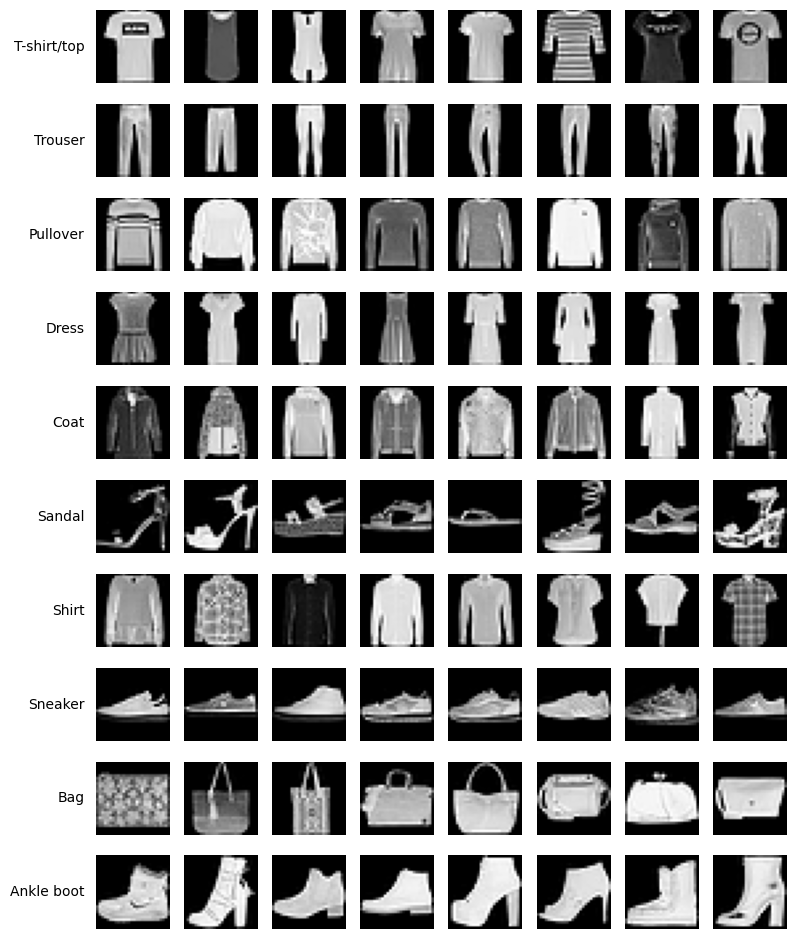

In [5]:
samples_per_class = 8

fig, axes = plt.subplots(
    cfg.num_classes, samples_per_class,
    figsize=(samples_per_class * 1.2, cfg.num_classes * 1.2),
)
fig.subplots_adjust(left=0.18)

targets = train_set.targets  # tensor (N,) berisi label seluruh data

for c in range(cfg.num_classes):
    idx = (targets == c).nonzero(as_tuple=True)[0][:samples_per_class]  # (samples_per_class,)
    batch = torch.stack([train_set[i][0] for i in idx])                 # (S, C, H, W)
    batch = (batch + 1) / 2                                             # balik ke [0, 1] untuk ditampilkan

    for j in range(samples_per_class):
        ax = axes[c, j]
        ax.imshow(batch[j, 0], cmap="gray", vmin=0, vmax=1)             # (H, W)
        ax.axis("off")
        if j == 0:
            ax.text(-0.15, 0.5, class_names[c], transform=ax.transAxes,
                    ha="right", va="center", fontsize=10)

plt.show()

## Sel 6: Verifikasi Visual

Tampilkan 32 gambar pertama dari satu batch dengan nama kelasnya, lalu 16 sampel acak kelas "Shirt" (ganti `SAMPLE_SEED` untuk sampel lain).

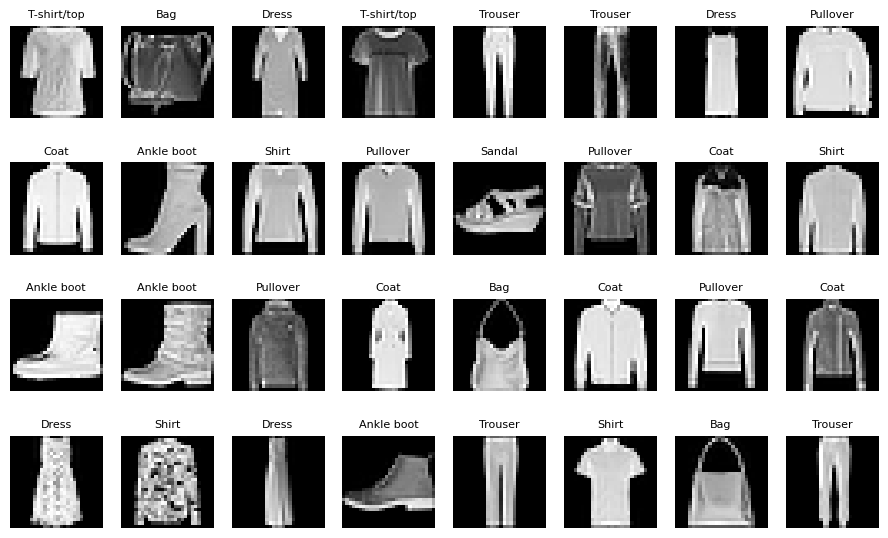

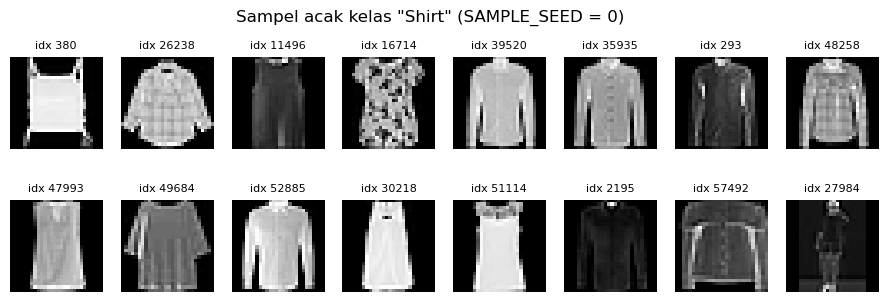

In [6]:
SAMPLE_SEED = 0          # ganti angka ini untuk melihat sampel "Shirt" yang lain
SHIRT_SAMPLES = 16       # jumlah sampel acak dari kelas "Shirt"

# --- Bagian 1: 32 gambar pertama dari satu batch, grid 4 x 8 ---
grid_rows, grid_cols = 4, 8
num_show = grid_rows * grid_cols                          # 32

batch_images, batch_labels = next(iter(train_loader))     # (B, C, H, W), (B,)
shown = (batch_images[:num_show] + 1) / 2                 # (32, C, H, W), balik ke [0, 1]

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(grid_cols * 1.4, grid_rows * 1.7))
for k, ax in enumerate(axes.flat):
    ax.imshow(shown[k, 0], cmap="gray", vmin=0, vmax=1)  # (H, W)
    ax.set_title(class_names[batch_labels[k].item()], fontsize=8)
    ax.axis("off")
plt.show()

# --- Bagian 2: sampel acak dari seluruh data kelas "Shirt" ---
shirt_label = class_names.index("Shirt")
shirt_idx = (train_set.targets == shirt_label).nonzero(as_tuple=True)[0]  # (N_shirt,)

sample_gen = torch.Generator().manual_seed(SAMPLE_SEED)
perm = torch.randperm(len(shirt_idx), generator=sample_gen)[:SHIRT_SAMPLES]  # (SHIRT_SAMPLES,)
chosen = shirt_idx[perm]                                                     # (SHIRT_SAMPLES,)

shirts = torch.stack([train_set[i][0] for i in chosen.tolist()])  # (SHIRT_SAMPLES, C, H, W)
shirts = (shirts + 1) / 2                                         # balik ke [0, 1]

shirt_cols = 8
shirt_rows = SHIRT_SAMPLES // shirt_cols
fig, axes = plt.subplots(shirt_rows, shirt_cols, figsize=(shirt_cols * 1.4, shirt_rows * 1.7))
for k, ax in enumerate(axes.flat):
    ax.imshow(shirts[k, 0], cmap="gray", vmin=0, vmax=1)  # (H, W)
    ax.set_title(f"idx {chosen[k].item()}", fontsize=8)
    ax.axis("off")
fig.suptitle(f'Sampel acak kelas "Shirt" (SAMPLE_SEED = {SAMPLE_SEED})')
plt.show()

## Sel 7: Konfigurasi Generator

Tambahkan `latent_dim` (ukuran noise `z`) dan `embed_dim` (ukuran embedding label) ke `Config` lewat subclass, tanpa mengubah Sel 2.

In [7]:
@dataclass
class GanConfig(Config):
    latent_dim: int = 100   # ukuran noise z
    embed_dim: int = 32     # ukuran embedding label


# Pertahankan nilai Config lama, lalu tambahkan field baru
cfg = GanConfig(**vars(cfg))
print(cfg)

GanConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32)


## Sel 8: Class Generator

Embedding label digabung (concat) dengan `z`, diproyeksikan ke peta fitur kecil, lalu di-upsample dengan `ConvTranspose2d` sampai ukuran gambar. Output `tanh` di [-1, 1].

In [8]:
import torch.nn as nn


class Generator(nn.Module):
    def __init__(self, cfg, base_channels=128):
        super().__init__()
        # Dua tahap upsample x2, jadi sisi gambar harus habis dibagi 4
        assert cfg.image_size % 4 == 0, "cfg.image_size harus habis dibagi 4"
        self.base_channels = base_channels
        self.init_size = cfg.image_size // 4  # 28 -> 7

        # Label (B,) int64 -> vektor (B, embed_dim)
        self.label_embed = nn.Embedding(cfg.num_classes, cfg.embed_dim)

        # (B, latent_dim + embed_dim) -> (B, base_channels * init_size * init_size)
        self.project = nn.Linear(
            cfg.latent_dim + cfg.embed_dim,
            base_channels * self.init_size ** 2,
        )

        self.net = nn.Sequential(
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),
            # (B, base, s, s) -> (B, base // 2, 2s, 2s)
            nn.ConvTranspose2d(base_channels, base_channels // 2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_channels // 2),
            nn.ReLU(inplace=True),
            # (B, base // 2, 2s, 2s) -> (B, C, 4s, 4s) = (B, C, H, W)
            nn.ConvTranspose2d(base_channels // 2, cfg.channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),  # output di [-1, 1], sama dengan normalisasi data
        )

    def forward(self, z, labels):
        # z: (B, latent_dim), labels: (B,) int64
        emb = self.label_embed(labels)                 # (B, embed_dim)
        x = torch.cat([z, emb], dim=1)                 # (B, latent_dim + embed_dim)
        x = self.project(x)                            # (B, base * s * s)
        x = x.view(x.size(0), self.base_channels, self.init_size, self.init_size)  # (B, base, s, s)
        return self.net(x)                             # (B, C, H, W)

## Sel 9: Uji Generator

Buat Generator, pindahkan ke `device`, beri `z` dan label acak, lalu cek shape output, rentang nilai, dan jumlah parameter.

In [9]:
generator = Generator(cfg).to(device)

z = torch.randn(cfg.batch_size, cfg.latent_dim, device=device)                  # (B, latent_dim)
labels = torch.randint(0, cfg.num_classes, (cfg.batch_size,), device=device)    # (B,) int64

with torch.no_grad():
    fake = generator(z, labels)                                                 # (B, C, H, W)

print(f"output shape   : {tuple(fake.shape)}")  # harapan: (128, 1, 28, 28)
print(f"output min/max : {fake.min().item():.3f} / {fake.max().item():.3f}")  # harus dalam [-1, 1]
print(f"jumlah parameter: {sum(p.numel() for p in generator.parameters()):,}")

output shape   : (128, 1, 28, 28)
output min/max : -1.000 / 1.000
jumlah parameter: 967,041


## Sel 10: Class Discriminator

Label di-embed jadi peta `(B, 1, H, W)`, ditumpuk ke gambar sebagai channel tambahan (concat), lalu dua konvolusi stride 2 dan satu Linear menghasilkan logit asli/palsu per gambar.

In [10]:
class Discriminator(nn.Module):
    def __init__(self, cfg, base_channels=64):
        super().__init__()
        # Dua tahap downsample /2, jadi sisi gambar harus habis dibagi 4
        assert cfg.image_size % 4 == 0, "cfg.image_size harus habis dibagi 4"
        self.image_size = cfg.image_size
        final_size = cfg.image_size // 4  # 28 -> 7

        # Label (B,) int64 -> satu nilai per piksel (B, H*W), nanti di-reshape jadi 1 channel
        self.label_embed = nn.Embedding(cfg.num_classes, cfg.image_size ** 2)

        self.net = nn.Sequential(
            # (B, C+1, H, W) -> (B, base, H/2, W/2)
            nn.Conv2d(cfg.channels + 1, base_channels, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            # (B, base, H/2, W/2) -> (B, 2*base, H/4, W/4)
            nn.Conv2d(base_channels, base_channels * 2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),  # (B, 2*base*final_size*final_size)
            nn.Linear(base_channels * 2 * final_size ** 2, 1),  # logit mentah, tanpa sigmoid
        )

    def forward(self, images, labels):
        # images: (B, C, H, W), labels: (B,) int64
        label_map = self.label_embed(labels)                                  # (B, H*W)
        label_map = label_map.view(-1, 1, self.image_size, self.image_size)   # (B, 1, H, W)
        x = torch.cat([images, label_map], dim=1)                             # (B, C+1, H, W)
        return self.net(x).squeeze(1)                                         # (B,)

## Sel 11: Uji Discriminator

Beri satu batch gambar asli dan satu batch gambar buatan Generator ke Discriminator, lalu cek shape logit, rentang nilainya, dan jumlah parameter.

In [11]:
discriminator = Discriminator(cfg).to(device)

real_images, real_labels = next(iter(train_loader))  # (B, C, H, W), (B,)
real_images, real_labels = real_images.to(device), real_labels.to(device)

z = torch.randn(cfg.batch_size, cfg.latent_dim, device=device)  # (B, latent_dim)

with torch.no_grad():
    fake_images = generator(z, real_labels)               # (B, C, H, W)
    real_logits = discriminator(real_images, real_labels) # (B,)
    fake_logits = discriminator(fake_images, real_labels) # (B,)

print(f"real logits shape : {tuple(real_logits.shape)}")  # harapan: (128,)
print(f"fake logits shape : {tuple(fake_logits.shape)}")  # harapan: (128,)
print(f"real logits min/max: {real_logits.min().item():.3f} / {real_logits.max().item():.3f}")
print(f"fake logits min/max: {fake_logits.min().item():.3f} / {fake_logits.max().item():.3f}")
print(f"jumlah parameter  : {sum(p.numel() for p in discriminator.parameters()):,}")

real logits shape : (128,)
fake logits shape : (128,)
real logits min/max: -0.977 / 1.210
fake logits min/max: -1.180 / 0.903
jumlah parameter  : 147,681


## Sel 12: Konfigurasi Training

Tambahkan `lr_g`, `lr_d`, dan `beta1` ke config lewat subclass, tanpa mengubah sel sebelumnya.

In [12]:
@dataclass
class TrainConfig(GanConfig):
    lr_g: float = 2e-4    # learning rate Generator
    lr_d: float = 2e-4    # learning rate Discriminator
    beta1: float = 0.5    # beta1 Adam (beta2 dibiarkan default 0.999)


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = TrainConfig(**vars(cfg))
print(cfg)

TrainConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0002, beta1=0.5)


## Sel 13: Fungsi Loss

`BCEWithLogitsLoss` dipakai untuk loss Discriminator (asli = 1, palsu = 0) dan loss Generator versi non-saturating (gambar palsu diberi target 1).

In [13]:
criterion = nn.BCEWithLogitsLoss()  # sigmoid + BCE dalam satu operasi, stabil secara numerik


def d_loss_fn(real_logits, fake_logits):
    # real_logits, fake_logits: (B,) logit mentah dari Discriminator
    real_loss = criterion(real_logits, torch.ones_like(real_logits))   # target asli = 1, hasil skalar
    fake_loss = criterion(fake_logits, torch.zeros_like(fake_logits))  # target palsu = 0, hasil skalar
    return real_loss + fake_loss


def g_loss_fn(fake_logits):
    # fake_logits: (B,); non-saturating: Generator ingin gambar palsunya dianggap asli (target 1)
    return criterion(fake_logits, torch.ones_like(fake_logits))

## Sel 14: Optimizer

Dua optimizer Adam terpisah untuk Generator dan Discriminator, dengan learning rate dan `beta1` dari `cfg`.

In [14]:
# Dua optimizer terpisah: satu untuk parameter Generator, satu untuk Discriminator
opt_g = torch.optim.Adam(generator.parameters(), lr=cfg.lr_g, betas=(cfg.beta1, 0.999))
opt_d = torch.optim.Adam(discriminator.parameters(), lr=cfg.lr_d, betas=(cfg.beta1, 0.999))

## Sel 15: Uji Loss dan Optimizer

Cek loss pada logit nol (nilainya bisa dihitung manual), loss pada logit dari Sel 11, dan kesesuaian optimizer dengan `cfg`.

In [15]:
# Logit nol berarti sigmoid = 0.5, jadi nilai loss bisa dihitung analitik
zero_logits = torch.zeros(cfg.batch_size, device=device)  # (B,)

print(f"d_loss (logit nol)    : {d_loss_fn(zero_logits, zero_logits).item():.4f}")  # harapan: 1.3863 (2 * ln 2)
print(f"g_loss (logit nol)    : {g_loss_fn(zero_logits).item():.4f}")               # harapan: 0.6931 (ln 2)

# Logit dari Sel 11 (model belum dilatih)
print(f"d_loss (logit Sel 11) : {d_loss_fn(real_logits, fake_logits).item():.4f}")
print(f"g_loss (logit Sel 11) : {g_loss_fn(fake_logits).item():.4f}")

for name, opt, lr in [("opt_g", opt_g, cfg.lr_g), ("opt_d", opt_d, cfg.lr_d)]:
    group = opt.param_groups[0]
    sesuai = group["lr"] == lr and group["betas"][0] == cfg.beta1
    print(f"{name}: lr={group['lr']}, betas={group['betas']}, sesuai cfg: {sesuai}")

d_loss (logit nol)    : 1.3863
g_loss (logit nol)    : 0.6931
d_loss (logit Sel 11) : 1.3341
g_loss (logit Sel 11) : 0.7125
opt_g: lr=0.0002, betas=(0.5, 0.999), sesuai cfg: True
opt_d: lr=0.0002, betas=(0.5, 0.999), sesuai cfg: True


## Sel 16: Konfigurasi Loop Training

Tambahkan `epochs`, `snap_per_class`, dan `ckpt_dir` (folder penyimpanan bobot) ke config lewat subclass.

In [16]:
@dataclass
class LoopConfig(TrainConfig):
    epochs: int = 50                    # jumlah epoch training
    snap_per_class: int = 8             # gambar per kelas pada snapshot Generator
    ckpt_dir: str = "./checkpoints/run_epochs50"     # folder penyimpanan bobot


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = LoopConfig(**vars(cfg))
print(cfg)

LoopConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0002, beta1=0.5, epochs=50, snap_per_class=8, ckpt_dir='./checkpoints/run_epochs50')


## Sel 17: Noise dan Label Tetap

Buat `fixed_z` dan `fixed_labels` (tiap kelas `snap_per_class` gambar) untuk snapshot Generator tiap epoch.

In [17]:
# Noise dan label tetap supaya snapshot antar epoch bisa dibandingkan
snap_gen = torch.Generator().manual_seed(SEED)
fixed_z = torch.randn(
    cfg.num_classes * cfg.snap_per_class, cfg.latent_dim, generator=snap_gen
).to(device)                                                                       # (N, latent_dim)
fixed_labels = torch.arange(cfg.num_classes).repeat_interleave(cfg.snap_per_class).to(device)  # (N,)

print(f"fixed_z shape      : {tuple(fixed_z.shape)}")
print(f"fixed_labels shape : {tuple(fixed_labels.shape)}")

fixed_z shape      : (80, 100)
fixed_labels shape : (80,)


## Sel 18: Fungsi `train_one_epoch`

Satu epoch penuh: update Discriminator lalu Generator di tiap batch. Mengembalikan rata-rata `loss_d`, `loss_g`, `D(real)`, dan `D(fake)`.

In [18]:
def train_one_epoch():
    # Jumlahkan sebagai tensor di device; .item() hanya dipanggil sekali di akhir epoch
    sums = torch.zeros(4, device=device)  # [loss_d, loss_g, D(real), D(fake)]

    for real_images, real_labels in train_loader:
        real_images = real_images.to(device)  # (B, C, H, W)
        real_labels = real_labels.to(device)  # (B,)
        batch_size = real_images.size(0)      # B, selalu sama karena drop_last=True

        z = torch.randn(batch_size, cfg.latent_dim, device=device)                     # (B, latent_dim)
        fake_labels = torch.randint(0, cfg.num_classes, (batch_size,), device=device)  # (B,)
        fake_images = generator(z, fake_labels)                                        # (B, C, H, W)

        # --- Update Discriminator ---
        real_logits = discriminator(real_images, real_labels)           # (B,)
        fake_logits = discriminator(fake_images.detach(), fake_labels)  # (B,), detach: gradien tidak masuk ke G
        loss_d = d_loss_fn(real_logits, fake_logits)
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()

        # --- Update Generator (D sudah diperbarui, gambar palsu tidak di-detach) ---
        loss_g = g_loss_fn(discriminator(fake_images, fake_labels))
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        sums += torch.stack([
            loss_d.detach(),
            loss_g.detach(),
            torch.sigmoid(real_logits.detach()).mean(),
            torch.sigmoid(fake_logits.detach()).mean(),
        ])

    loss_d_avg, loss_g_avg, d_real_avg, d_fake_avg = (sums / len(train_loader)).tolist()
    return {"loss_d": loss_d_avg, "loss_g": loss_g_avg, "d_real": d_real_avg, "d_fake": d_fake_avg}

## Sel 19: Loop Training

Jalankan `cfg.epochs` epoch, catat `history`, simpan snapshot Generator, dan timpa checkpoint bobot (`cgan_last.pt`) di akhir tiap epoch.

In [19]:
import time
from pathlib import Path

ckpt_path = Path(cfg.ckpt_dir) / "cgan_last.pt"
ckpt_path.parent.mkdir(parents=True, exist_ok=True)

history = {"loss_d": [], "loss_g": [], "d_real": [], "d_fake": []}
snapshots = []  # satu elemen per epoch: (N, C, H, W) di CPU, rentang [-1, 1]

generator.train()
discriminator.train()
print(f"Checkpoint disimpan di: {ckpt_path.resolve()}")

for epoch in range(1, cfg.epochs + 1):
    start = time.time()
    stats = train_one_epoch()
    for key, value in stats.items():
        history[key].append(value)

    # Snapshot dari noise tetap; eval() supaya BatchNorm tidak memakai statistik batch snapshot
    generator.eval()
    with torch.no_grad():
        snapshots.append(generator(fixed_z, fixed_labels).cpu())  # (N, C, H, W)
    generator.train()

    # Timpa checkpoint tiap epoch supaya epoch terakhir yang selesai tidak hilang
    torch.save({
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
    }, ckpt_path)

    print(
        f"Epoch {epoch:>3}/{cfg.epochs} | loss_d {stats['loss_d']:.4f} | loss_g {stats['loss_g']:.4f} | "
        f"D(real) {stats['d_real']:.3f} | D(fake) {stats['d_fake']:.3f} | {time.time() - start:.1f}s"
    )

Checkpoint disimpan di: /Users/maulidahelyati/Library/CloudStorage/GoogleDrive-maulida.helya@gmail.com/My Drive/Tugas Gen AI/Tugas_Vibe_Coding/notebooks/checkpoints/run_epochs50/cgan_last.pt
Epoch   1/50 | loss_d 0.9820 | loss_g 1.2635 | D(real) 0.632 | D(fake) 0.368 | 8.3s
Epoch   2/50 | loss_d 0.8677 | loss_g 1.3314 | D(real) 0.667 | D(fake) 0.329 | 8.3s
Epoch   3/50 | loss_d 0.9313 | loss_g 1.3208 | D(real) 0.656 | D(fake) 0.343 | 8.2s
Epoch   4/50 | loss_d 1.0958 | loss_g 1.1337 | D(real) 0.605 | D(fake) 0.394 | 8.3s
Epoch   5/50 | loss_d 1.1692 | loss_g 1.0685 | D(real) 0.583 | D(fake) 0.416 | 8.4s
Epoch   6/50 | loss_d 1.2014 | loss_g 1.0173 | D(real) 0.572 | D(fake) 0.428 | 8.3s
Epoch   7/50 | loss_d 1.2131 | loss_g 0.9966 | D(real) 0.567 | D(fake) 0.432 | 8.7s
Epoch   8/50 | loss_d 1.2257 | loss_g 0.9840 | D(real) 0.564 | D(fake) 0.436 | 8.5s
Epoch   9/50 | loss_d 1.2319 | loss_g 0.9813 | D(real) 0.562 | D(fake) 0.438 | 8.1s
Epoch  10/50 | loss_d 1.2341 | loss_g 0.9770 | D(real

## Sel 20: Konfigurasi Gambar

Tambahkan `fig_dir` (folder penyimpanan PNG) ke config lewat subclass.

In [20]:
@dataclass
class EvalConfig(LoopConfig):
    fig_dir: str = "./figures/run_epochs50"    # folder penyimpanan gambar (PNG)


# Pertahankan nilai config lama, lalu tambahkan field baru
cfg = EvalConfig(**vars(cfg))
print(cfg)

EvalConfig(image_size=28, channels=1, num_classes=10, batch_size=128, num_workers=0, data_root='./data', latent_dim=100, embed_dim=32, lr_g=0.0002, lr_d=0.0002, beta1=0.5, epochs=50, snap_per_class=8, ckpt_dir='./checkpoints/run_epochs50', fig_dir='./figures/run_epochs50')


## Sel 21: Kurva Training

Plot `loss_d` dan `loss_g`, serta `D(real)` dan `D(fake)` per epoch. Garis putus-putus di 0.5 menandai titik seimbang. Gambar disimpan ke `fig_dir`.

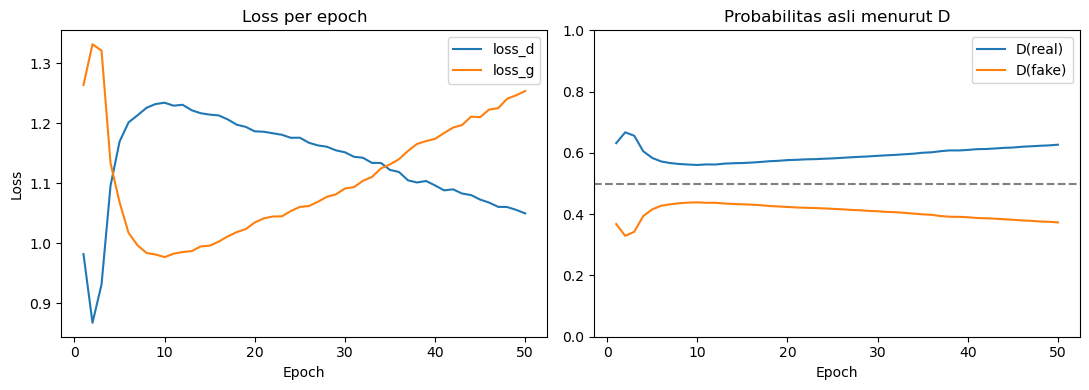

In [21]:
from pathlib import Path

fig_dir = Path(cfg.fig_dir)
fig_dir.mkdir(parents=True, exist_ok=True)

epoch_axis = range(1, len(history["loss_d"]) + 1)

fig, (ax_loss, ax_prob) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss.plot(epoch_axis, history["loss_d"], label="loss_d")
ax_loss.plot(epoch_axis, history["loss_g"], label="loss_g")
ax_loss.set_title("Loss per epoch")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Loss")
ax_loss.legend()

ax_prob.plot(epoch_axis, history["d_real"], label="D(real)")
ax_prob.plot(epoch_axis, history["d_fake"], label="D(fake)")
ax_prob.axhline(0.5, linestyle="--", color="gray")  # titik seimbang: D tidak bisa membedakan
ax_prob.set_ylim(0, 1)
ax_prob.set_title("Probabilitas asli menurut D")
ax_prob.set_xlabel("Epoch")
ax_prob.legend()

fig.tight_layout()
fig.savefig(fig_dir / "01_kurva_training.png", dpi=150)
plt.show()

## Sel 22: Snapshot Generator per Epoch

Tampilkan snapshot dari `fixed_z` pada beberapa epoch terpilih, satu baris per kelas, untuk melihat perkembangan gambar. Gambar disimpan ke `fig_dir`.

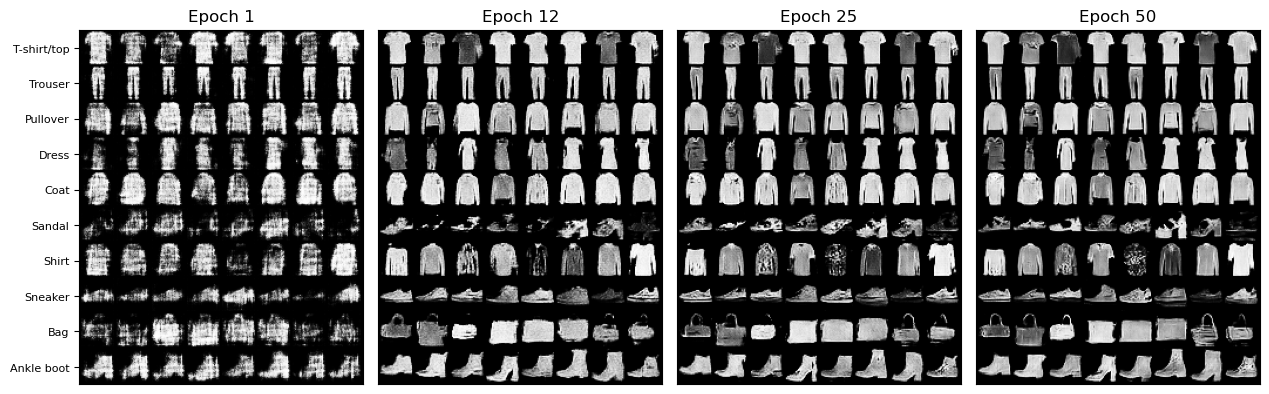

In [22]:
from torchvision.utils import make_grid

# Epoch terpilih (1-based): awal, seperempat, setengah, dan akhir
last_epoch = len(snapshots)
snap_epochs = sorted({1, max(1, last_epoch // 4), max(1, last_epoch // 2), last_epoch})

fig, axes = plt.subplots(1, len(snap_epochs), figsize=(len(snap_epochs) * 3.2, 6.5))
for k, (ax, ep) in enumerate(zip(np.atleast_1d(axes), snap_epochs)):
    imgs = (snapshots[ep - 1] + 1) / 2                           # (N, C, H, W), balik ke [0, 1]
    grid = make_grid(imgs, nrow=cfg.snap_per_class, padding=2)   # (3, H', W'), satu baris per kelas
    ax.imshow(grid.permute(1, 2, 0))                             # (H', W', 3)
    ax.set_title(f"Epoch {ep}")
    ax.set_xticks([])
    if k == 0:
        row_h = grid.shape[1] / cfg.num_classes
        ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
        ax.set_yticklabels(class_names, fontsize=8)
    else:
        ax.set_yticks([])

fig.tight_layout()
fig.savefig(fig_dir / "02_snapshot_per_epoch.png", dpi=150)
plt.show()

## Sel 23: Hasil Akhir per Kelas

Buat gambar dengan `z` baru (ganti `EVAL_SEED` untuk sampel lain), satu baris per kelas. Baris yang isinya mirip semua menandakan kemungkinan mode collapse. Gambar disimpan ke `fig_dir`.

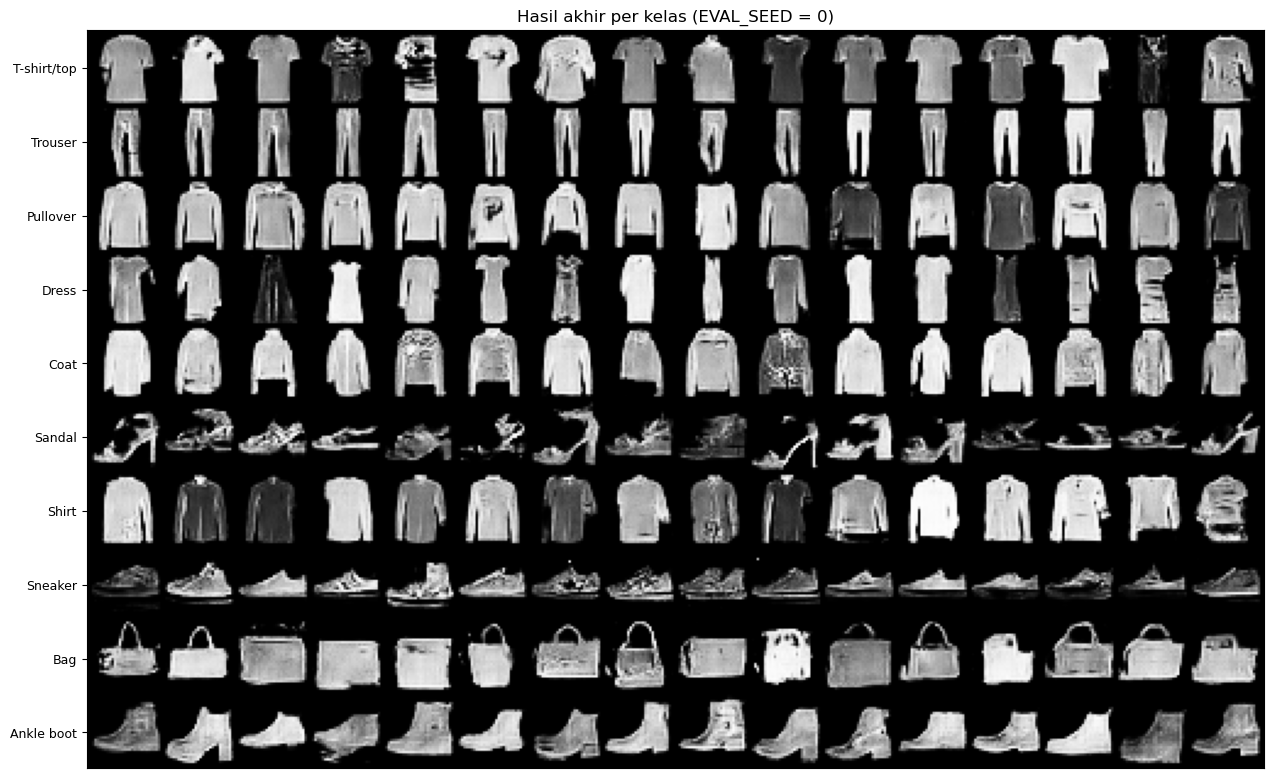

In [23]:
EVAL_SEED = 0          # ganti angka ini untuk melihat sampel lain
EVAL_PER_CLASS = 16    # gambar per kelas

eval_gen = torch.Generator().manual_seed(EVAL_SEED)
eval_z = torch.randn(
    cfg.num_classes * EVAL_PER_CLASS, cfg.latent_dim, generator=eval_gen
).to(device)                                                                                  # (N, latent_dim)
eval_labels = torch.arange(cfg.num_classes).repeat_interleave(EVAL_PER_CLASS).to(device)      # (N,)

generator.eval()
with torch.no_grad():
    eval_images = (generator(eval_z, eval_labels).cpu() + 1) / 2   # (N, C, H, W), balik ke [0, 1]
generator.train()

grid = make_grid(eval_images, nrow=EVAL_PER_CLASS, padding=2)      # (3, H', W'), satu baris per kelas

fig, ax = plt.subplots(figsize=(EVAL_PER_CLASS * 0.8, cfg.num_classes * 0.8))
ax.imshow(grid.permute(1, 2, 0))                                   # (H', W', 3)
ax.set_xticks([])
row_h = grid.shape[1] / cfg.num_classes
ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
ax.set_yticklabels(class_names, fontsize=9)
ax.set_title(f"Hasil akhir per kelas (EVAL_SEED = {EVAL_SEED})")

fig.tight_layout()
fig.savefig(fig_dir / "03_hasil_akhir_per_kelas.png", dpi=150)
plt.show()

## Sel 24: Metrik Keragaman

Bandingkan rata-rata jarak L2 antar gambar buatan dengan antar gambar asli per kelas. Rasio yang jauh di bawah 1 menandakan keragaman Generator lebih rendah dari data asli. Ini indikator kasar, bacalah bersama grid gambar.

In [24]:
DIV_SAMPLES = 64  # jumlah gambar per kelas untuk menghitung keragaman


def mean_pairwise_l2(x):
    # x: (N, C, H, W) di [0, 1] -> rata-rata jarak L2 antar pasangan gambar berbeda
    flat = x.flatten(start_dim=1)                # (N, C*H*W)
    dist = torch.cdist(flat, flat)               # (N, N), diagonal = 0
    n = flat.size(0)
    return (dist.sum() / (n * (n - 1))).item()


div_gen = torch.Generator().manual_seed(EVAL_SEED)

print(f"{'Kelas':<14}{'asli':>8}{'buatan':>9}{'rasio':>8}")
generator.eval()
with torch.no_grad():
    for c in range(cfg.num_classes):
        # Gambar buatan: DIV_SAMPLES noise berbeda, label tetap c
        z = torch.randn(DIV_SAMPLES, cfg.latent_dim, generator=div_gen).to(device)  # (S, latent_dim)
        labels = torch.full((DIV_SAMPLES,), c, dtype=torch.long, device=device)     # (S,)
        fake = (generator(z, labels).cpu() + 1) / 2                                 # (S, C, H, W)

        # Gambar asli: DIV_SAMPLES sampel acak dari kelas c
        idx = (train_set.targets == c).nonzero(as_tuple=True)[0]                    # (N_c,)
        pick = idx[torch.randperm(len(idx), generator=div_gen)[:DIV_SAMPLES]]       # (S,)
        real = (torch.stack([train_set[i][0] for i in pick.tolist()]) + 1) / 2      # (S, C, H, W)

        real_div, fake_div = mean_pairwise_l2(real), mean_pairwise_l2(fake)
        print(f"{class_names[c]:<14}{real_div:>8.3f}{fake_div:>9.3f}{fake_div / real_div:>8.2f}")
generator.train()

Kelas             asli   buatan   rasio
T-shirt/top      8.904    8.672    0.97
Trouser          6.461    6.732    1.04
Pullover         8.847    9.361    1.06
Dress            8.553    7.777    0.91
Coat             9.127    8.870    0.97
Sandal           8.556    8.414    0.98
Shirt            9.015    9.629    1.07
Sneaker          6.700    6.510    0.97
Bag             11.346   10.465    0.92
Ankle boot       8.777    8.638    0.98


Generator(
  (label_embed): Embedding(10, 32)
  (project): Linear(in_features=132, out_features=6272, bias=True)
  (net): Sequential(
    (0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): Tanh()
  )
)

## Sel 25: Diagnosis BatchNorm, Statistik

Buat gambar dari `z` yang sama dengan salinan Generator di mode `eval()` dan `train()`. Hook mengukur selisih statistik running BatchNorm terhadap statistik batch (`mean_gap` dan `var_ratio`). Makin jauh dari 0 dan 1, makin besar kemungkinan bercak hitam berasal dari mode `eval()`.

In [25]:
import copy

# Salinan Generator, supaya statistik BatchNorm generator asli tidak ikut berubah
gen_eval = copy.deepcopy(generator).eval()    # statistik rata-rata (running), seperti di Sel 22 dan 23
gen_train = copy.deepcopy(generator).train()  # statistik batch saat ini

bn_gaps = []  # satu elemen per layer BatchNorm: (jumlah channel, mean_gap, var_ratio)


def record_bn_gap(module, inputs):
    # Dipanggil tepat sebelum BatchNorm bekerja, jadi running stats belum ikut diperbarui
    x = inputs[0].detach()                                 # (B, C, H, W)
    batch_mean = x.mean(dim=(0, 2, 3))                     # (C,)
    batch_var = x.var(dim=(0, 2, 3), unbiased=False)       # (C,)
    # mean_gap: selisih mean dalam satuan std batch; var_ratio: varians running / varians batch
    mean_gap = ((module.running_mean - batch_mean).abs() / batch_var.sqrt().clamp_min(1e-5)).mean().item()
    var_ratio = (module.running_var / batch_var.clamp_min(1e-5)).mean().item()
    bn_gaps.append((module.num_features, mean_gap, var_ratio))


hooks = [m.register_forward_pre_hook(record_bn_gap)
         for m in gen_train.modules() if isinstance(m, nn.BatchNorm2d)]

with torch.no_grad():
    imgs_eval = (gen_eval(eval_z, eval_labels).cpu() + 1) / 2     # (N, C, H, W), [0, 1]
    imgs_train = (gen_train(eval_z, eval_labels).cpu() + 1) / 2   # (N, C, H, W), [0, 1]

for h in hooks:
    h.remove()

for num_features, mean_gap, var_ratio in bn_gaps:
    print(f"BatchNorm ({num_features:>3} channel): mean_gap = {mean_gap:.3f}, var_ratio = {var_ratio:.3f}")
print(f"Rata-rata |eval - train| per piksel: {(imgs_eval - imgs_train).abs().mean().item():.4f}")

BatchNorm (128 channel): mean_gap = 0.014, var_ratio = 0.987
BatchNorm ( 64 channel): mean_gap = 0.005, var_ratio = 0.994
Rata-rata |eval - train| per piksel: 0.0071


## Sel 26: Diagnosis BatchNorm, Gambar

Bandingkan hasil kedua mode secara visual (8 gambar per kelas). Gambar disimpan ke `fig_dir`.

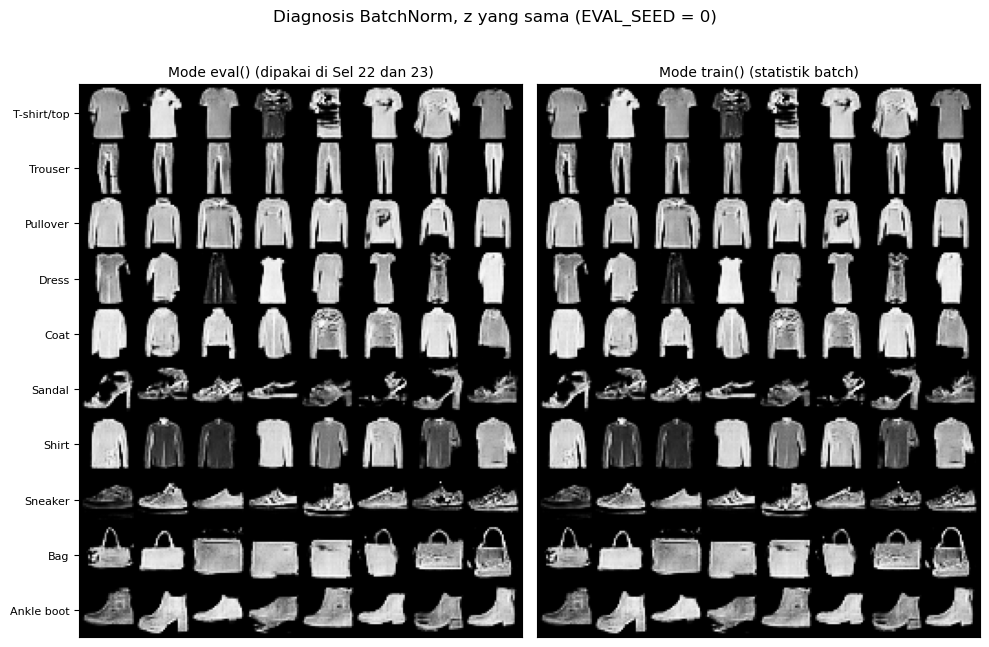

In [26]:
diag_per_class = 8  # gambar per kelas yang ditampilkan di tiap panel


def first_k_per_class(imgs, k):
    # imgs: (num_classes * EVAL_PER_CLASS, C, H, W), berurutan per kelas -> (num_classes * k, C, H, W)
    return imgs.view(cfg.num_classes, EVAL_PER_CLASS, *imgs.shape[1:])[:, :k].reshape(-1, *imgs.shape[1:])


panels = [("Mode eval() (dipakai di Sel 22 dan 23)", imgs_eval),
          ("Mode train() (statistik batch)", imgs_train)]

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for k, (ax, (title, imgs)) in enumerate(zip(axes, panels)):
    grid = make_grid(first_k_per_class(imgs, diag_per_class), nrow=diag_per_class, padding=2)  # (3, H', W')
    ax.imshow(grid.permute(1, 2, 0))                                                           # (H', W', 3)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    if k == 0:
        row_h = grid.shape[1] / cfg.num_classes
        ax.set_yticks([(r + 0.5) * row_h for r in range(cfg.num_classes)])
        ax.set_yticklabels(class_names, fontsize=8)
    else:
        ax.set_yticks([])

fig.suptitle(f"Diagnosis BatchNorm, z yang sama (EVAL_SEED = {EVAL_SEED})")
fig.tight_layout()
fig.savefig(fig_dir / "04_diagnosis_bn_eval_vs_train.png", dpi=150)
plt.show()